# **Step 3 – Limpieza y preprocesamiento de datos**
**Proyecto TA – Análisis de Datos (1INF03, 2026-2) – Equipo E10**

> *KDD, paso 3:* «Data cleaning and preprocessing: basic operations such as the removal of noise and strategies for handling missing data fields.»

Entradas: ficha nominal (`0_crudos`) y `1_consolidados/step2a_nutricion_2026.csv`.
Salidas (en `datos/2_limpios/`):
- `step3_evaluaciones.csv` – **tabla de modelado**: una fila por evaluación (niño × mes) con medidas y etiqueta de la ficha del mismo mes.
- `step3_panel.csv` – ficha limpia, una fila por niño y mes.
- `step3_nutricion.csv` – Bloque 2 limpio (diagnósticos normalizados).
- `step3_ninos_anexo.csv` – una fila por niño con las variables de la ficha, **sin imputar** (insumo del Anexo).

Convención: se imprime el tamaño antes y después de cada operación que elimina filas o columnas, y cada decisión se justifica por escrito.

## Librerías, rutas y funciones auxiliares
`norm` crea una clave de texto comparable (sin tildes, minúsculas, espacios colapsados) sin alterar el dato original; `parse_fecha` convierte fechas formato por formato.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re, json, unicodedata
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
RAW, CONS = Path("../datos/0_crudos"), Path("../datos/1_consolidados")
OUT, RES, FIG = Path("../datos/2_limpios"), Path("../datos/4_resultados"), Path("../figuras")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110

def norm(s):
    s = unicodedata.normalize("NFKD", str(s))
    return re.sub(r"\s+", " ", "".join(ch for ch in s if not unicodedata.combining(ch))).strip().lower()

def parse_fecha(s):
    f = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    for fmt in ["%d/%m/%Y", "%d/%m/%y"]:
        m = f.isna() & s.notna(); f[m] = pd.to_datetime(s[m], format=fmt, errors="coerce")
    return f

## 1. Lectura de la ficha
Se leen todos los campos como texto para decidir explícitamente cómo tratar cada valor.

In [2]:
raw = pd.read_csv(RAW/"ficha_nominal/FichaNominal_consolidado_IDs_v2.txt", sep="|", dtype=str, keep_default_na=False, encoding="utf-8")
print("Tamaño inicial:", raw.shape)
df = raw.copy()

Tamaño inicial: (2667, 33)


## 2. Limpieza de texto y vacíos disfrazados
Los campos traen saltos de línea y espacios sobrantes (`'Saludable\r\r\n'` contaría como una categoría distinta de `'Saludable'`), y los vacíos llegan como `''` o `'NA'`, que pandas no reconoce como nulos. Se unifican antes de cualquier otro paso.

In [3]:
for c in df.columns:
    df[c] = df[c].str.replace(r"\s+", " ", regex=True).str.strip()
antes = int(raw.isin(["", "NA"]).sum().sum())
df = df.replace({"": np.nan, "NA": np.nan})
print("Vacíos disfrazados convertidos a NaN:", antes, "| vacíos reales ahora:", int(df.isna().sum().sum()), "| tamaño:", df.shape)

Vacíos disfrazados convertidos a NaN: 436 | vacíos reales ahora: 436 | tamaño: (2667, 33)


## 3. Fechas
Se convierten las cinco fechas formato por formato. `No tiene` en la fecha del PTI significa que el plan no existe y pasa a NaT. Se comprueba que **no se pierda ninguna fecha válida** comparando conteos antes y después.

In [4]:
cols_fecha = {"Fecha de nacimiento":"nac", "Fecha de ingreso":"ingreso", "Fecha de la Resolucion Administrativa":"fecha_resol",
              "Fecha del Oficio de Ingreso":"fecha_oficio", "FECHA ELABORACIÓN Plan de Trabajo individual - PTI":"fecha_pti"}
resumen = []
for c, nuevo in cols_fecha.items():
    s = df[c].where(df[c] != "No tiene")
    df[nuevo] = parse_fecha(s)
    resumen.append({"columna": c, "valores no vacíos": int(s.notna().sum()), "fechas válidas": int(df[nuevo].notna().sum())})
resumen = pd.DataFrame(resumen); resumen["perdidas"] = resumen["valores no vacíos"] - resumen["fechas válidas"]
resumen

,columna,valores no vacíos,fechas válidas,perdidas
0,Fecha de nacimiento,2667,2667,0
1,Fecha de ingreso,2667,2667,0
2,Fecha de la Resolucion Administrativa,2485,2485,0
3,Fecha del Oficio de Ingreso,2609,2609,0
4,FECHA ELABORACIÓN Plan de Trabajo individual -...,1635,1635,0


**Resultado.** `perdidas = 0` en las cinco columnas: todas las fechas se convirtieron sin pérdida.

## 4. Identificador de niño y duplicados
Como 4 IDs agrupan a más de un niño (Step 2b), se construye la **clave de niño** = ID + sexo + fecha de nacimiento. Luego se buscan duplicados **completos** y **parciales** (mismo niño y periodo).

In [5]:
df["id_nna"] = df["IDs_FichaNominal"] + "_" + df["Sexo"] + "_" + df["nac"].dt.strftime("%Y%m%d")
n_ids, n_ninos = df["IDs_FichaNominal"].nunique(), df["id_nna"].nunique()
print("IDs originales:", n_ids, "-> niños distintos (clave corregida):", n_ninos)
print("Duplicados completos:", int(df.duplicated().sum()), "| parciales (mismo niño y periodo):", int(df.duplicated(subset=["periodo","id_nna"], keep=False).sum()))

IDs originales: 157 -> niños distintos (clave corregida): 164
Duplicados completos: 0 | parciales (mismo niño y periodo): 0


**Resultado.** Los 157 IDs corresponden a **164 niños** distintos. No hay duplicados completos ni parciales: corregir la clave elimina las "repeticiones" aparentes (los 36 registros de `PPA_FN_0020` eran 5 niños).

### 4.1 Edad y tiempo en el hogar (reglas de consistencia)
- **Fecha de referencia:** fin del mes del registro (la ficha es mensual).
- **Edad negativa:** el niño no puede figurar antes de nacer → error de captura, se **excluye** la fila.
- **Ingreso anterior al nacimiento o posterior al registro:** fecha inválida → NaT; el tiempo en el hogar se imputará en el Anexo. Se agrega el indicador `ingreso_imputado`.

In [6]:
df["ref"] = pd.to_datetime(df["periodo"].str.replace("_","-") + "-01") + pd.offsets.MonthEnd(0)
df["edad"] = (df["ref"] - df["nac"]).dt.days / 365.25
n0 = len(df); neg = df["edad"] < 0
print("Filas con edad negativa:", int(neg.sum()), "->", df.loc[neg, ["periodo","id_nna"]].values.tolist())
df = df[~neg].copy(); print("Tamaño: antes", n0, "-> después", len(df))
inv = (df["ingreso"] < df["nac"]) | (df["ingreso"] > df["ref"])
n_inv, n_inv_ninos = int(inv.sum()), df.loc[inv, "id_nna"].nunique()
print("Filas con fecha de ingreso inválida:", n_inv, "| niños afectados:", n_inv_ninos)
df["ingreso_imputado"] = inv.astype(int)
df.loc[inv, "ingreso"] = pd.NaT
df["tiempo_hogar_meses"] = (df["ref"] - df["ingreso"]).dt.days / 30.44

Filas con edad negativa: 2 -> [['2025_02', 'PPA_FN_0153_M_20250528'], ['2025_02', 'PPA_FN_0020_M_20250601']]
Tamaño: antes 2667 -> después 2665
Filas con fecha de ingreso inválida: 87 | niños afectados: 15


## 5. Variables sin información o redundantes
Una variable constante no discrimina y una redundante duplica información. Cada descarte se respalda con evidencia calculada.

In [7]:
ev_desc = []
def dom(col): s = df[col].dropna(); return round(100*s.value_counts(normalize=True).iloc[0], 1)
for c in ["Comunicado_DGA","Seguro de Salud (NNA)","Acceso a capacitación técnico productiva","Juzgado/UPE","Tipo de documento",
          "Observaciones y/o comentarios de la forma de ingreso de la NNA"]:
    ev_desc.append({"variable": c, "motivo": "casi constante", "evidencia": f"{dom(c)} % de las filas tienen el mismo valor"})
nac_ = (df["Nacionalidad"].map(norm).str.replace("peruano","peruana") == "peruana").mean()
ev_desc.append({"variable":"Nacionalidad","motivo":"sin información","evidencia":f"tras unificar el género gramatical, {100*nac_:.0f} % es 'peruana'"})
for c, nuevo in [("Fecha de la Resolucion Administrativa","fecha_resol"),("Fecha del Oficio de Ingreso","fecha_oficio")]:
    ok = df[[nuevo,"ingreso"]].dropna()
    ev_desc.append({"variable":c,"motivo":"redundante con fecha de ingreso",
                    "evidencia": f"coincide con la fecha de ingreso en {100*(ok[nuevo]==ok['ingreso']).mean():.0f} % de las filas con ambos datos"})
iguales = (df["Instancia que elabora el PTI"].map(norm).str.replace("upe ","").str.replace("-"," ") ==
           df["Nombre de UPE /Juzgado"].map(norm).str.replace("upe ","").str.replace("-"," ")).mean()
ev_desc.append({"variable":"Instancia que elabora el PTI","motivo":"redundante con UPE","evidencia":f"coincide con la UPE en {100*iguales:.0f} % de las filas"})
ev_desc.append({"variable":"Provincia / Distrito","motivo":"alta cardinalidad y vacíos","evidencia":f"{df['Distrito'].nunique()} distritos, {df['Distrito'].isna().mean()*100:.1f} % vacío; se resume en 'nacido_en_lima'"})
ev_desc.append({"variable":"Grado de Instrucción","motivo":"redundante","evidencia":"colineal con la edad y con el nivel educativo logrado"})
ev_desc.append({"variable":"VIGENCIA DEL PTI","motivo":"texto libre mezclado","evidencia":"fechas, '12 meses', 'Permanencia en el Car'; el estado del PTI ya la resume"})
pd.set_option("display.max_colwidth", 120); pd.DataFrame(ev_desc)

,variable,motivo,evidencia
0,Comunicado_DGA,casi constante,100.0 % de las filas tienen el mismo valor
1,Seguro de Salud (NNA),casi constante,99.9 % de las filas tienen el mismo valor
2,Acceso a capacitación técnico productiva,casi constante,98.9 % de las filas tienen el mismo valor
3,Juzgado/UPE,casi constante,99.9 % de las filas tienen el mismo valor
4,Tipo de documento,casi constante,99.2 % de las filas tienen el mismo valor
5,Observaciones y/o comentarios de la forma de ingreso de la NNA,casi constante,96.6 % de las filas tienen el mismo valor
6,Nacionalidad,sin información,"tras unificar el género gramatical, 100 % es 'peruana'"
7,Fecha de la Resolucion Administrativa,redundante con fecha de ingreso,coincide con la fecha de ingreso en 58 % de las filas con ambos datos
8,Fecha del Oficio de Ingreso,redundante con fecha de ingreso,coincide con la fecha de ingreso en 64 % de las filas con ambos datos
9,Instancia que elabora el PTI,redundante con UPE,coincide con la UPE en 88 % de las filas


## 6. Normalización de categorías y variables derivadas
Cada categórica tiene variantes de escritura de una misma idea. Se agrupan con reglas explícitas y se verifica que **ninguna fila quede sin clasificar**.

In [8]:
out = pd.DataFrame(index=df.index)
out["id_nna"], out["IDs_FichaNominal"], out["periodo"], out["nac"], out["sexo"] = df["id_nna"], df["IDs_FichaNominal"], df["periodo"], df["nac"], df["Sexo"]
out["edad"], out["tiempo_hogar_meses"], out["ingreso_imputado"] = df["edad"], df["tiempo_hogar_meses"], df["ingreso_imputado"]
out["nacido_en_lima"] = df["Departamento"].map(norm).isin(["lima","callao"]).astype(int)

def situacion(s):
    s = norm(s)
    return "Provisional" if "provisional" in s else "Definitiva" if "definitiva" in s else "Urgente" if "urgente" in s else "Otra"
out["situacion_legal"] = df["Situación Legal de la (NNA)"].map(situacion)

def upe(s):
    s = norm(s).replace("-", " ")
    return ("Lima Norte-Callao" if "norte callao" in s else "Lima Este" if s.endswith("este") else "Lima Sur" if s.endswith("sur")
            else "Lima" if s == "upe lima" else "Otra")
out["upe"] = df["Nombre de UPE /Juzgado"].map(upe)
out["estado_pti"] = df["ESTADO DEL PTI"].map(norm).map({"actual":"Actual","vencido":"Vencido","no tiene":"No tiene"})
out["nivel_educativo"] = df["Último nivel educativo logrado"].map(norm).map({"ninguno":"Ninguno","inicial":"Inicial","primaria":"Primaria","secundaria":"Secundaria","tecnico":"Técnico"})
out["estudia"] = df["La NNA actualmente estudia"].map(norm).map({"si":1,"no":0})

def tipo_ie(s):
    s = norm(s)
    return ("EBR" if "regular" in s else "CEBE (especial)" if "cebe" in s else "EBA (alternativa)" if ("ceba" in s or "alternativa" in s)
            else "Técnica/taller" if ("tecnico" in s or "taller" in s) else "Ninguna" if "ninguno" in s else None)
out["tipo_ie"] = df["Tipo de Institución Educativa"].map(tipo_ie)

sal = df["Estado de Salud Física Actual"].map(norm)
out["anemia"] = sal.str.contains("anemia").astype(int)
out["otra_condicion_salud"] = (~sal.str.contains("anemia|saludable|proceso")).astype(int)
dis = df["Presenta Discapacidad (Indicar tipo de discapacidad)"].map(norm)
out["tiene_discapacidad"] = (dis != "no tiene").astype(int)
out["severidad_discapacidad"] = np.select([dis=="no tiene", dis.str.contains("leve"), dis.str.contains("moderad"), dis.str.contains("sever")], [0,1,2,3], default=np.nan)
sop = df["Soporte Psico-emocional"].map(norm)
out["soporte_acompanamiento"] = sop.str.contains("acom|acop").astype(int)
out["soporte_psicoterapia"]   = sop.str.contains("psico|terapia").astype(int)
out["soporte_estimulacion"]   = sop.str.contains("estimul|tempana").astype(int)
out["soporte_taller"]         = sop.str.contains("taller").astype(int)
out["n_tipos_soporte"] = out[["soporte_acompanamiento","soporte_psicoterapia","soporte_estimulacion","soporte_taller"]].sum(axis=1)
out["salud_mental_especializada"] = (df["Atención en Salud mental especializada"].map(norm) == "si recibe").astype(int)
out["atencion_psicologica"] = (df["Atenciones de salud psicológica"].map(norm) == "si").astype(int)

sin_clasificar = out[["situacion_legal","upe","estado_pti","nivel_educativo","estudia","tipo_ie"]].isna().sum()
print("Filas sin clasificar por variable:", sin_clasificar.to_dict())
for c in ["situacion_legal","upe","estado_pti","nivel_educativo","tipo_ie"]: print("#", c, out[c].value_counts().to_dict())
print("Sin ningún soporte:", int((out["n_tipos_soporte"]==0).sum()), "filas | severidad sin especificar:", int(out["severidad_discapacidad"].isna().sum()))

Filas sin clasificar por variable: {'situacion_legal': 0, 'upe': 0, 'estado_pti': 0, 'nivel_educativo': 0, 'estudia': 0, 'tipo_ie': 0}
# situacion_legal {'Provisional': 2184, 'Definitiva': 235, 'Urgente': 192, 'Otra': 54}
# upe {'Lima Norte-Callao': 896, 'Lima Este': 771, 'Lima': 740, 'Lima Sur': 187, 'Otra': 71}
# estado_pti {'Actual': 1059, 'No tiene': 1030, 'Vencido': 576}
# nivel_educativo {'Primaria': 1222, 'Secundaria': 798, 'Inicial': 413, 'Ninguno': 182, 'Técnico': 50}
# tipo_ie {'EBR': 2320, 'Ninguna': 196, 'CEBE (especial)': 70, 'Técnica/taller': 50, 'EBA (alternativa)': 29}
Sin ningún soporte: 1091 filas | severidad sin especificar: 1


**Interpretación.**
- Las reglas clasifican el 100 % de las filas (ninguna categoría queda sin asignar).
- `Soporte Psico-emocional` (53 variantes) se convierte en 4 indicadores (acompañamiento, psicoterapia/terapia, estimulación temprana, talleres) y un conteo; `Nuevo ingreso` y `No` cuentan como *sin soporte*.
- `Discapacidad` se resume en presencia (0/1) y severidad ordinal (0–3); un único registro `Mental` sin severidad queda como NaN.
- El lugar de nacimiento se resume en `nacido_en_lima` (Lima o Callao), porque el distrito está muy fragmentado.

## 7. Variable objetivo
`Nivel Nutricional` mezcla estados simples y combinaciones con errores de escritura. Se **descompone cada texto en componentes** (obesidad, sobrepeso, riesgo de sobrepeso, talla baja, talla baja severa, riesgo de talla baja, saludable) y se define:
- **`alteracion_estricta` (principal) = 1** si hay exceso de peso (sobrepeso u obesidad) o retraso de talla (talla baja o severa); **0** si es saludable o solo tiene *riesgos*.
- **`alteracion` (sensibilidad) = 1** si hay *cualquier* componente distinto de saludable, incluidos los riesgos; **0** si es saludable.
- `En proceso de evaluación` **no es un diagnóstico**: queda sin etiqueta (NaN) y no se usa para entrenar.

In [9]:
def componentes(txt):
    t = norm(txt).replace("tallay", "talla y").replace("riesgode", "riesgo de")
    if "proceso" in t: return None
    comps = set()
    for p in re.split(r"\s+y\s+", t):
        p = p.strip()
        if p == "saludable": comps.add("saludable")
        elif "obesidad" in p: comps.add("obesidad")
        elif "riesgo" in p and "sobrepeso" in p: comps.add("riesgo_sobrepeso")
        elif "sobrepeso" in p: comps.add("sobrepeso")
        elif "riesgo" in p and "talla" in p: comps.add("riesgo_talla_baja")
        elif "severa" in p: comps.add("talla_baja_severa")
        elif "talla" in p: comps.add("talla_baja")
        else: raise ValueError("Sin clasificar: " + p)
    return comps
comp = df["Nivel Nutricional"].map(componentes)
ESTRICTOS = {"obesidad", "sobrepeso", "talla_baja", "talla_baja_severa"}
out["nutri_componentes"] = comp.map(lambda c: "sin_diagnostico" if c is None else "+".join(sorted(c)))
out["alteracion"] = comp.map(lambda c: np.nan if c is None else int(c != {"saludable"}))
out["alteracion_estricta"] = comp.map(lambda c: np.nan if c is None else int(bool(c & ESTRICTOS)))
for k in ["obesidad","sobrepeso","riesgo_sobrepeso","talla_baja","talla_baja_severa","riesgo_talla_baja"]:
    out["dx_"+k] = comp.map(lambda c, k=k: np.nan if c is None else int(k in c))
con_dx = comp.notna()
print("Filas con diagnóstico:", int(con_dx.sum()), "| sin diagnóstico ('en proceso'):", int((~con_dx).sum()))
print("Prevalencia en filas con diagnóstico: estricta =", round(100*out["alteracion_estricta"].mean(),1), "% | amplia =", round(100*out["alteracion"].mean(),1), "%")
print(out[[c for c in out.columns if c.startswith("dx_")]].sum().astype(int).to_string())

Filas con diagnóstico: 2489 | sin diagnóstico ('en proceso'): 176
Prevalencia en filas con diagnóstico: estricta = 40.6 % | amplia = 68.8 %
dx_obesidad             405
dx_sobrepeso            359
dx_riesgo_sobrepeso     485
dx_talla_baja           248
dx_talla_baja_severa     57
dx_riesgo_talla_baja    630


Se grafica cuántos registros tienen cada componente.

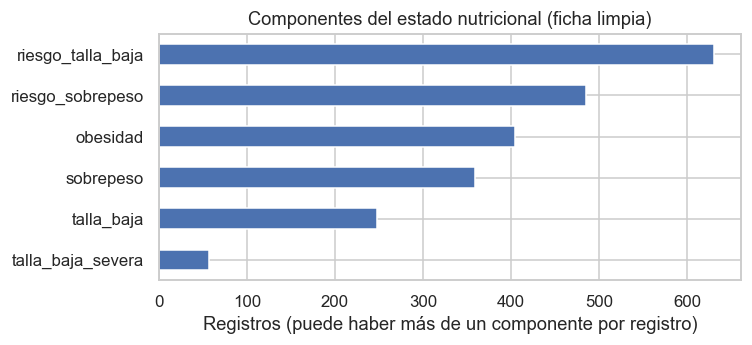

In [10]:
fig, ax = plt.subplots(figsize=(7,3.3))
out[[c for c in out.columns if c.startswith("dx_")]].sum().rename(lambda s: s[3:]).sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Registros (puede haber más de un componente por registro)"); ax.set_title("Componentes del estado nutricional (ficha limpia)")
plt.tight_layout(); plt.savefig(FIG/"step3_componentes_nutricionales.png", bbox_inches="tight"); plt.show()

**Interpretación.** Las 29 variantes de texto quedan en 6 componentes interpretables y dos etiquetas binarias. De las 2 489 filas con diagnóstico, el **40,6 %** tiene alteración estricta y el **68,8 %** la amplia; 176 filas están *en proceso* y no se etiquetan. La etiqueta estricta es más equilibrada; la amplia está desbalanceada hacia la alteración, por lo que en el modelado se usarán ponderación de clases y métricas distintas de la exactitud.

## 8. Ficha limpia por niño y mes (panel)
Se guarda la ficha limpia.

In [11]:
panel = out.copy()
print("Panel limpio:", panel.shape, "| niños:", panel["id_nna"].nunique())
panel.to_csv(OUT/"step3_panel.csv", index=False, sep="|", encoding="utf-8")

Panel limpio: (2665, 35) | niños: 164


## 9. Estabilidad de la etiqueta en la ficha
Se mide cuántas veces cambia la etiqueta de un mismo niño a lo largo de los 19 meses. Si casi no cambia, la ficha se actualiza poco, lo que importa para interpretar el cruce con las mediciones.

In [12]:
dx = panel.dropna(subset=["alteracion_estricta"]).sort_values(["id_nna","periodo"])
est = dx.groupby("id_nna")[["alteracion_estricta","alteracion"]].nunique()
n_varios = int((dx.groupby("id_nna").size() > 1).sum())
cambia_e, cambia_a = int((est["alteracion_estricta"] > 1).sum()), int((est["alteracion"] > 1).sum())
print("Niños con diagnóstico:", len(est), "| con más de un registro diagnosticado:", n_varios)
print("Niños cuya etiqueta cambió alguna vez: estricta =", cambia_e, "| amplia =", cambia_a)

Niños con diagnóstico: 150 | con más de un registro diagnosticado: 145
Niños cuya etiqueta cambió alguna vez: estricta = 0 | amplia = 0


**Interpretación.** De los 150 niños con diagnóstico, 145 tienen más de un registro y **ninguno cambió de etiqueta** (ni estricta ni amplia) en 19 meses. La etiqueta de la ficha es muy estable: o el estado nutricional no cambia, o la ficha se **actualiza con rezago**. Esto se tendrá en cuenta al contrastarla con las mediciones (§14).

## 10. Tabla por niño (insumo del Anexo)
El Anexo evalúa la hipótesis descartada (predecir solo con variables de la ficha). Usa **un registro por niño**: el último con diagnóstico. Se guarda **sin imputar**; la imputación se ajusta en el Anexo solo con el conjunto de entrenamiento.

In [13]:
ninos = dx.groupby("id_nna").tail(1).copy()
ninos["n_registros_dx"] = ninos["id_nna"].map(dx.groupby("id_nna").size())
ninos = ninos.rename(columns={"periodo": "periodo_ref"}).reset_index(drop=True)
cols_anexo = ["id_nna","periodo_ref","edad","sexo","tiempo_hogar_meses","ingreso_imputado","nacido_en_lima","situacion_legal","upe","estado_pti",
              "nivel_educativo","estudia","tipo_ie","anemia","otra_condicion_salud","tiene_discapacidad","severidad_discapacidad",
              "soporte_acompanamiento","soporte_psicoterapia","soporte_estimulacion","soporte_taller","n_tipos_soporte",
              "salud_mental_especializada","atencion_psicologica","n_registros_dx","nutri_componentes","alteracion","alteracion_estricta"]
ninos = ninos[cols_anexo]
for c in ["alteracion","alteracion_estricta","estudia"]: ninos[c] = ninos[c].astype(int)
vac = ninos.isna().sum(); print("Niños:", len(ninos), "| excluidos por no tener ningún diagnóstico:", panel["id_nna"].nunique() - len(ninos))
print("Vacíos (se imputan en el Anexo):", vac[vac > 0].to_dict())
ninos.to_csv(OUT/"step3_ninos_anexo.csv", index=False, sep="|", encoding="utf-8")

Niños: 150 | excluidos por no tener ningún diagnóstico: 14
Vacíos (se imputan en el Anexo): {'tiempo_hogar_meses': 4}


## 11. Bloque 2: normalización de diagnósticos
Los diagnósticos tienen errores de escritura (`OBESIDA`, `RIESO TALLA BAJA`, `NORNAL`, `ALTA`). Se llevan a categorías canónicas con reglas explícitas; un valor no reconocido detiene la ejecución. Perímetro cefálico (98 % vacío) y presión arterial (95 %) se descartan.

In [14]:
nut = pd.read_csv(CONS/"step2a_nutricion_2026.csv", sep="|")
print("Tamaño inicial:", nut.shape)
def diag(s):
    if pd.isna(s): return np.nan
    s = norm(s)
    if re.search(r"ries|rieg|rieso", s):
        if re.search(r"obe|sobre", s): return "Riesgo sobrepeso"
        if re.search(r"tall|tala", s): return "Riesgo talla baja"
        return "Riesgo bajo peso"
    if "obe" in s: return "Obesidad"
    if "sobre" in s: return "Sobrepeso"
    if "bajo peso severo" in s: return "Bajo peso severo"
    if "bajo peso" in s: return "Bajo peso"
    if "desnutr" in s: return "Desnutrido"
    if "talla baja severa" in s: return "Talla baja severa"
    if "talla baja" in s: return "Talla baja"
    if re.match(r"^alt", s): return "Alto"
    if re.match(r"^nor", s): return "Normal"
    raise ValueError("diagnóstico sin clasificar: " + s)
cols_dx = ["P/E_OMS","T/E_OMS","P/T_OMS","IMC_OMS","P/E_INS","T/E_INS","P/T_INS","IMC_INS"]
for c in cols_dx: nut[c] = nut[c].map(diag)
nut = nut.drop(columns=["Perimetro_cefalico","Presion_arterial"])
for c in ["T/E_OMS","IMC_OMS"]: print(c, nut[c].value_counts().to_dict())
print("Tamaño final:", nut.shape)

Tamaño inicial: (379, 20)
T/E_OMS {'Normal': 191, 'Riesgo talla baja': 87, 'Talla baja': 58, 'Talla baja severa': 27, 'Alto': 14}
IMC_OMS {'Normal': 175, 'Riesgo sobrepeso': 88, 'Sobrepeso': 58, 'Obesidad': 25, 'Riesgo bajo peso': 12, 'Bajo peso': 3}
Tamaño final: (379, 18)


## 12. Bloque 2: valores atípicos
Se aplica la regla del rango intercuartílico (Q1 − 1,5·RIC, Q3 + 1,5·RIC) a peso, talla e IMC, de forma global y dentro de cada grupo de edad (comparación más justa, porque las medidas dependen de la edad). **No se eliminan automáticamente**: primero se revisa si son errores o datos reales.

 variable  atípicos globales  atípicos dentro de su grupo de edad  de ellos con IMC OMS sobrepeso/obesidad
  Peso_kg                  2                                   11                                        2
 Talla_cm                  0                                    1                                        0
IMC_valor                 11                                   12                                        9
IDs_FichaNominal periodo  edad_ev  Peso_kg  Talla_cm  IMC_valor   IMC_OMS
     PPA_FN_0101 2026_06     14.0     78.9     160.7       30.6  Obesidad
     PPA_FN_0102 2026_01     14.9     88.7     167.8       31.5 Sobrepeso
     PPA_FN_0044 2026_08     17.5     75.4     153.5       31.8 Sobrepeso
     PPA_FN_0102 2026_06     15.3     93.8     170.9       32.1  Obesidad
     PPA_FN_0030 2026_01     13.1     75.3     150.5       33.2 Sobrepeso
     PPA_FN_0102 2026_04     15.1     95.4     168.0       33.8 Sobrepeso
     PPA_FN_0030 2026_04     13.4     77.3     150.7  

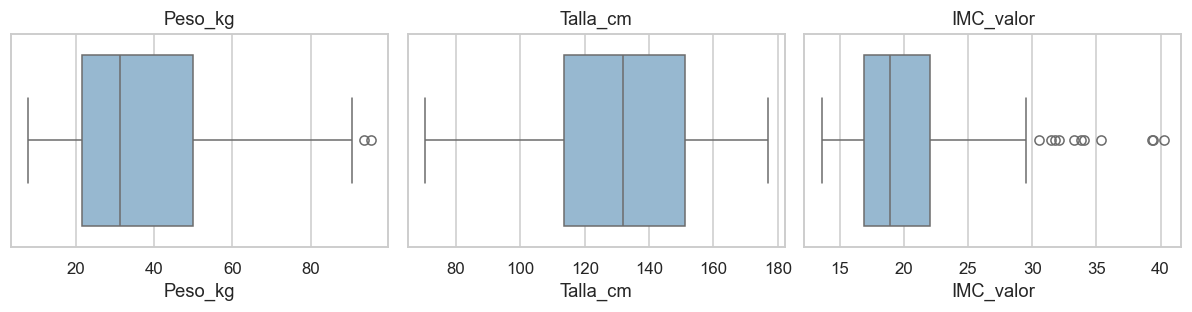

In [15]:
nut["edad_ev"] = (pd.to_datetime(nut["periodo"].str.replace("_","-") + "-15") - pd.to_datetime(nut["nac"])).dt.days / 365.25
nut["grupo_edad"] = pd.cut(nut["edad_ev"], [-1,5,11,17,40], labels=["0-5","6-11","12-17","18+"])
def fuera(s): q1, q3 = s.quantile([.25,.75]); r = q3-q1; return (s < q1-1.5*r) | (s > q3+1.5*r)
atip = []
for c in ["Peso_kg","Talla_cm","IMC_valor"]:
    g = fuera(nut[c]); gg = nut.groupby("grupo_edad", observed=True)[c].transform(fuera).astype(bool)
    atip.append({"variable": c, "atípicos globales": int(g.sum()), "atípicos dentro de su grupo de edad": int(gg.sum()),
                 "de ellos con IMC OMS sobrepeso/obesidad": int(nut.loc[g, "IMC_OMS"].isin(["Sobrepeso","Obesidad"]).sum())})
print(pd.DataFrame(atip).to_string(index=False))
print(nut.loc[fuera(nut["IMC_valor"]), ["IDs_FichaNominal","periodo","edad_ev","Peso_kg","Talla_cm","IMC_valor","IMC_OMS"]].round(1).sort_values("IMC_valor").to_string(index=False))
fig, axs = plt.subplots(1, 3, figsize=(11,3))
for ax, c in zip(axs, ["Peso_kg","Talla_cm","IMC_valor"]): sns.boxplot(x=nut[c], ax=ax, color="#8EBAD9"); ax.set_title(c)
plt.tight_layout(); plt.savefig(FIG/"step3_boxplots_medidas.png", bbox_inches="tight"); plt.show()
nut.to_csv(OUT/"step3_nutricion.csv", index=False, sep="|", encoding="utf-8")

**Interpretación.** Los atípicos son pocos: 2 pesos y 11 IMC en el análisis global, y **9 de los 11 IMC altos son de niños que la propia OMS clasifica con sobrepeso u obesidad** (los otros dos son de `PPA_FN_0054`, de 28 años, que queda fuera por edad en §13). Son el fenómeno de interés, no errores de medición, por eso **no se eliminan**. Dentro de cada grupo de edad los conteos cambian (11 pesos, 12 IMC), pero tampoco indican errores: reflejan la mezcla de edades y estados nutricionales.

## 13. Tabla de evaluaciones (medición × ficha del mismo mes)
**Unidad de análisis del modelo:** una evaluación = un niño en un mes. La etiqueta se toma de la ficha **del mismo mes**.

**Regla de cruce.** Se une por **periodo + ID**. La fecha de nacimiento solo se usa para distinguir a los niños de los 4 IDs reutilizados, porque en 4 niños la fecha difiere entre la ficha y el Bloque 2 (Step 2b) y un cruce por fecha los perdería. La edad de la evaluación se calcula con la fecha del Bloque 2 (registrada por la nutricionista, confirmada por la edad escrita), al día 15 del mes.

In [16]:
REUTILIZADOS = ["PPA_FN_0010", "PPA_FN_0020", "PPA_FN_0025", "PPA_FN_0127"]
pan = panel[["periodo","IDs_FichaNominal","nac","id_nna","sexo","alteracion","alteracion_estricta"]].copy()
pan["nac"] = pan["nac"].dt.strftime("%Y-%m-%d")
nut_r = nut["IDs_FichaNominal"].isin(REUTILIZADOS)
m1 = nut[~nut_r].merge(pan[~pan["IDs_FichaNominal"].isin(REUTILIZADOS)].drop(columns="nac"), on=["periodo","IDs_FichaNominal"], how="inner")
m2 = nut[nut_r].merge(pan[pan["IDs_FichaNominal"].isin(REUTILIZADOS)], on=["periodo","IDs_FichaNominal","nac"], how="inner")
ev = pd.concat([m1, m2], ignore_index=True)
sin_ficha = nut.merge(ev[["periodo","IDs_FichaNominal"]], how="left", indicator=True).query("_merge == 'left_only'")
print("Evaluaciones del Bloque 2:", len(nut), "| cruzadas con la ficha del mismo mes:", len(ev), "| sin ficha:", len(sin_ficha))
print("Sin ficha por periodo:", sin_ficha["periodo"].value_counts().to_dict())
assert ev.duplicated(["id_nna","periodo"]).sum() == 0
dif_nac = ev.merge(pan[["id_nna","periodo","nac"]].rename(columns={"nac": "nac_ficha"}), on=["id_nna","periodo"])
dif_nac = dif_nac[dif_nac["nac"] != dif_nac["nac_ficha"]]
print("Evaluaciones con fecha de nacimiento distinta entre ficha y Bloque 2 (recuperadas por esta regla):", len(dif_nac),
      "| niños:", dif_nac["IDs_FichaNominal"].nunique())

Evaluaciones del Bloque 2: 379 | cruzadas con la ficha del mismo mes: 342 | sin ficha: 37
Sin ficha por periodo: {'2026_08': 32, '2026_01': 4, '2026_02': 1}
Evaluaciones con fecha de nacimiento distinta entre ficha y Bloque 2 (recuperadas por esta regla): 10 | niños: 4


Se aplican las exclusiones: sin diagnóstico en la ficha (`en proceso`) y evaluaciones de mayores de 19 años (fuera del rango de las referencias OMS y de la población NNA).

In [17]:
n0 = len(ev)
sin_dx = ev["alteracion_estricta"].isna(); print("Sin diagnóstico en la ficha excluidas:", int(sin_dx.sum()))
ev = ev[~sin_dx]
ev["sexo_m"] = (ev["sexo"] == "M").astype(int)
mayor = ev["edad_ev"] > 19
print("Mayores de 19 años excluidas:", int(mayor.sum()), "| niños:", ev.loc[mayor, "id_nna"].nunique(), "| edades:", ev.loc[mayor, "edad_ev"].round(1).tolist())
ev = ev[~mayor].reset_index(drop=True)
for c in ["alteracion","alteracion_estricta"]: ev[c] = ev[c].astype(int)
print("Tamaño: antes", n0, "-> después", len(ev))
print("Nulos en las variables del modelo:", int(ev[["edad_ev","sexo_m","Peso_kg","Talla_cm","IMC_valor"]].isna().sum().sum()))
por_nino = ev.groupby("id_nna").size()
print("Evaluaciones:", len(ev), "| niños:", ev["id_nna"].nunique(), "| por niño: mediana", int(por_nino.median()), ", mín.", por_nino.min(), ", máx.", por_nino.max())
print("Prevalencia: estricta =", round(100*ev["alteracion_estricta"].mean(),1), "% | amplia =", round(100*ev["alteracion"].mean(),1), "%")
print("Evaluaciones por mes:", ev["periodo"].value_counts().sort_index().to_dict())

Sin diagnóstico en la ficha excluidas: 15
Mayores de 19 años excluidas: 3 | niños: 1 | edades: [28.2, 28.4, 28.6]
Tamaño: antes 342 -> después 324
Nulos en las variables del modelo: 0
Evaluaciones: 324 | niños: 121 | por niño: mediana 3 , mín. 1 , máx. 5
Prevalencia: estricta = 37.3 % | amplia = 66.7 %
Evaluaciones por mes: {'2026_01': 121, '2026_02': 4, '2026_03': 4, '2026_04': 98, '2026_06': 97}


**Interpretación.**
- De 379 evaluaciones, **342 se cruzan** con la ficha del mismo mes. No se cruzan 37: las 32 de agosto (no hay ficha de ese mes) y 5 de enero–febrero de 4 niños que no figuran en la ficha de ese mes.
- La regla de cruce por periodo + ID **recupera 10 evaluaciones de 4 niños** cuya fecha de nacimiento difiere entre ficha y Bloque 2; con un cruce por fecha se habrían perdido.
- Se excluyen 15 evaluaciones con ficha *en proceso* y 3 de un adulto de 28 años. Quedan **324 evaluaciones de 121 niños**, con 1 a 5 evaluaciones por niño (mediana 3).
- Prevalencia: **37,3 %** con alteración estricta y **66,7 %** con la amplia.
- Es una muestra pequeña con **medidas repetidas**: dos evaluaciones del mismo niño se parecen mucho. Por eso la partición entrenamiento/prueba será **por niño** (Step 4).

## 14. Concordancia entre la ficha y la clasificación OMS de las medidas
Sobre la misma tabla de evaluaciones se compara, por componente, lo que dice la ficha con la clasificación OMS que la institución calculó a partir de las medidas: **exceso de peso** (ficha: sobrepeso u obesidad; medición: IMC OMS sobrepeso u obesidad) y **talla baja** (ficha: talla baja o severa; medición: T/E OMS talla baja o severa).

In [18]:
dxs = panel[["id_nna","periodo","dx_obesidad","dx_sobrepeso","dx_talla_baja","dx_talla_baja_severa"]]
m = ev.merge(dxs, on=["id_nna","periodo"])
m["exceso_ficha"] = ((m["dx_obesidad"]==1)|(m["dx_sobrepeso"]==1)).astype(int); m["exceso_med"] = m["IMC_OMS"].isin(["Obesidad","Sobrepeso"]).astype(int)
m["talla_ficha"] = ((m["dx_talla_baja"]==1)|(m["dx_talla_baja_severa"]==1)).astype(int); m["talla_med"] = m["T/E_OMS"].isin(["Talla baja","Talla baja severa"]).astype(int)
conc = {}
for a, b, n in [("exceso_ficha","exceso_med","Exceso de peso (ficha vs IMC-OMS)"), ("talla_ficha","talla_med","Talla baja (ficha vs T/E-OMS)")]:
    conc[a] = 100*(m[a]==m[b]).mean()
    print(f"\n{n}: concordancia = {conc[a]:.1f} %"); print(pd.crosstab(m[a], m[b], rownames=["ficha"], colnames=["medición"]).to_string())


Exceso de peso (ficha vs IMC-OMS): concordancia = 76.9 %
medición    0   1
ficha            
0         206  33
1          42  43

Talla baja (ficha vs T/E-OMS): concordancia = 82.1 %
medición    0   1
ficha            
0         235  48
1          10  31


**Interpretación.** La ficha **se parece a las mediciones, pero no las replica**: concuerda en el **76,9 %** de las evaluaciones en exceso de peso y en el **82,1 %** en talla baja. En exceso de peso, la ficha marca como "sin exceso" a 33 evaluaciones que la medición clasifica con exceso, y 42 al revés; en talla baja, 48 evaluaciones con talla baja medida no figuran así en la ficha. Junto con la estabilidad de la etiqueta (§9), esto sugiere que la ficha **se actualiza con rezago** o combina varios indicadores (OMS e INS, P/E, P/T). Por eso el análisis se plantea como **auditoría**: la etiqueta es el registro manual de la ficha, no una réplica de la regla OMS.

## 15. Guardado de la tabla de evaluaciones

In [19]:
cols_ev = ["id_nna","periodo","casa","edad_ev","sexo_m","Peso_kg","Talla_cm","IMC_valor","alteracion","alteracion_estricta"] + cols_dx
ev[cols_ev].to_csv(OUT/"step3_evaluaciones.csv", index=False, sep="|", encoding="utf-8")
print("Guardado:", ev[cols_ev].shape)
ev[cols_ev].head(3).T

Guardado: (324, 18)


,0,1,2
id_nna,PPA_FN_0117_F_20230912,PPA_FN_0140_M_20240722,PPA_FN_0146_F_20230106
periodo,2026_01,2026_01,2026_01
casa,INFANTES,INFANTES,INFANTES
edad_ev,2.3436,1.483915,3.025325
sexo_m,0,1,0
Peso_kg,14.3,13.95,13.4
Talla_cm,86.2,81.0,88.3
IMC_valor,19.245159,21.262003,17.18634
alteracion,0,1,0
alteracion_estricta,0,0,0


## 16. Reporte de preprocesamiento

| # | Paso | Filas / columnas | Justificación |
|---|---|---|---|
| 1 | Limpieza de texto y vacíos disfrazados | 2 667 × 33; 436 vacíos a NaN | `\r\n`, espacios, `''` y `NA` impedían agrupar y contar nulos |
| 2 | Fechas a datetime (3 formatos) | 0 pérdidas | Evitar confundir día/mes |
| 3 | Clave de niño (ID + sexo + nacimiento) | 157 IDs → 164 niños | 4 IDs agrupaban niños distintos |
| 4 | Duplicados | 0 completos, 0 parciales | Verificación de integridad |
| 5 | Edad negativa | se excluyen 2 filas → 2 665 | Nacimiento posterior al registro |
| 6 | Ingreso inválido | 87 filas (15 niños) → NaT + indicador | Ingreso < nacimiento o > registro |
| 7 | Variables sin información / redundantes | 13 descartes con evidencia (§5) | Constantes o duplicadas |
| 8 | Normalización y variables derivadas | 100 % de filas clasificadas | Variantes de escritura |
| 9 | Etiquetas | 29 variantes → 6 componentes → `alteracion_estricta` (principal) y `alteracion` | Texto libre con combinaciones y errores |
| 10 | Tabla por niño (Anexo) | 150 niños, sin imputar | Insumo de la hipótesis descartada |
| 11 | Bloque 2 | 379 filas; diagnósticos normalizados; 2 columnas casi vacías descartadas | Errores de escritura |
| 12 | Atípicos | 2 pesos, 11 IMC (RIC), **no eliminados** | Casos reales de exceso de peso |
| 13 | Tabla de evaluaciones | 379 → 342 cruzadas → **324 evaluaciones, 121 niños** | Medidas + etiqueta del mismo mes; cruce por periodo + ID |
| 14 | Concordancia ficha vs OMS | 76,9 % exceso, 82,1 % talla | Motiva el enfoque de auditoría |

## Verificación y cifras de este notebook

In [20]:
assert (n_ids, n_ninos) == (157, 164) and len(df) == 2665 and (n_inv, n_inv_ninos) == (87, 15)
assert int(con_dx.sum()) == 2489 and round(100*panel["alteracion_estricta"].mean(), 1) == 40.6
assert (cambia_e, cambia_a) == (0, 0) and len(ninos) == 150
assert len(dif_nac) == 10 and len(sin_ficha) == 37
assert len(ev) == 324 and ev["id_nna"].nunique() == 121
assert round(100*ev["alteracion_estricta"].mean(), 1) == 37.3 and round(100*ev["alteracion"].mean(), 1) == 66.7
assert round(conc["exceso_ficha"], 1) == 76.9 and round(conc["talla_ficha"], 1) == 82.1
cifras = {"ninos_ficha": n_ninos, "evaluaciones": len(ev), "ninos_eval": int(ev["id_nna"].nunique()),
          "evaluaciones_cruzadas": 342, "recuperadas_por_cruce": len(dif_nac),
          "prev_estricta": round(100*ev["alteracion_estricta"].mean(), 1), "prev_amplia": round(100*ev["alteracion"].mean(), 1),
          "conc_exceso": round(conc["exceso_ficha"], 1), "conc_talla": round(conc["talla_ficha"], 1), "ninos_anexo": len(ninos)}
json.dump(cifras, open(RES/"cifras_step3.json", "w"), indent=1); cifras

{'ninos_ficha': 164,
 'evaluaciones': 324,
 'ninos_eval': 121,
 'evaluaciones_cruzadas': 342,
 'recuperadas_por_cruce': 10,
 'prev_estricta': np.float64(37.3),
 'prev_amplia': np.float64(66.7),
 'conc_exceso': np.float64(76.9),
 'conc_talla': np.float64(82.1),
 'ninos_anexo': 150}

## Declaración de uso de IA
Se usó **Claude Code (Anthropic)** para reorganizar el código del Step 3 anterior, corregir el cruce ficha–medición (por periodo + ID en lugar de por fecha de nacimiento) y unificar el cálculo de concordancias en un solo cruce. El equipo verificó cada regla con los conteos impresos y los `assert` de la celda anterior.

Siguiente: `Anexo_Step4_solo_ficha.ipynb` (hipótesis descartada) y `Step4_Reduccion_y_Proyeccion.ipynb`.